# 01 Data: pull, profile and build the model table

- What it does: downloads Boston's food establishment inspections once, profiles them, and builds one row per routine inspection with leak-free history features.
- Inputs: the Analyze Boston CKAN API (or the saved snapshot `data/raw/inspections_snapshot.parquet`).
- Outputs: `data/raw/inspections_snapshot.parquet`, `data/raw/pull_metadata.json`, `data/processed/inspections_full.parquet`, `data/processed/model_table.parquet`, `results/figures/reinspection_gap.png`.

In [1]:
import sys
sys.path.insert(0, "..")          # so `from src import ...` works when run from notebooks/

import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_pull import pull_inspections
from src import features as F

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)

## 1. Pull the data once

The pull selects only the columns we need and never requests the owner-name columns.
It takes every "Eating & Drinking" inspection up to the snapshot date. Inspections before 2016 are kept as history for the features, and the model table itself starts in 2016.

If the snapshot file already exists, the pull is skipped. Set `FORCE_PULL = True` to refresh it. A fresh pull is compared with the fingerprint in `docs/pull_metadata.json`, because the city can still edit old rows.

In [2]:
FORCE_PULL = False
raw = pull_inspections(raw_dir="../data/raw", force=FORCE_PULL)
meta = json.load(open("../data/raw/pull_metadata.json"))
print({k: meta[k] for k in ["pulled_at_utc", "source", "license", "row_count"]})
print(meta["sql"])

Snapshot found, skipping the pull: ../data/raw/inspections_snapshot.parquet


Snapshot matches the reference in docs/pull_metadata.json.
{'pulled_at_utc': '2026-11-11T21:37:09+00:00', 'source': 'https://data.boston.gov/dataset/food-establishment-inspections', 'license': 'Open Data Commons Public Domain Dedication and License (PDDL)', 'row_count': 785315}
SELECT "_id", "licenseno", "businessname", "descript", "licstatus", "result", "resultdttm", "viol_level", "viol_status", "violdesc", "comments", "issdttm", "zip", "city" FROM "4582bec6-2b4f-4f9e-bc55-cbaa73117f4c" WHERE "resultdttm" < '2026-11-11' AND "descript" LIKE 'Eating & Drinking%' ORDER BY "_id" LIMIT <page> OFFSET <n>


## 2. Profile the raw snapshot

The raw table has one row per violation, so one inspection can span many rows.

In [3]:
print("shape:", raw.shape)
print("unique licenses:", raw["licenseno"].nunique())
for col in ["result", "descript", "viol_level", "viol_status"]:
    print(f"\n{col}:")
    print(raw[col].value_counts(dropna=False).to_string())

shape: (785315, 14)
unique licenses: 8146

result:
result
HE_Fail       334307
HE_Pass       249345
HE_Filed       79239
HE_FailExt     68059
HE_Hearing     24282
HE_NotReq      17780
HE_TSOP         6618
HE_VolClos      2848
HE_OutBus       1544
HE_Closure       533
Pass             345
HE_FAILNOR       138
Fail             129
HE_Misc          100
DATAERR           34
HE_Hold           11
Closed             2
NoViol             1

descript:
descript
Eating & Drinking                443093
Eating & Drinking w/ Take Out    342222

viol_level:
viol_level
*       517735
***     113511
**      103849
NaN      50219
1919         1

viol_status:
viol_status
Fail    405970
Pass    332420
NaN      46925


In [4]:
raw_date = pd.to_datetime(raw["resultdttm"].str.slice(0, 19))
print("data runs from", raw_date.min().date(), "to", raw_date.max().date())

per_year = pd.DataFrame({
    "violation_rows": raw.groupby(raw_date.dt.year).size(),
    "license_days": raw.assign(d=raw_date.dt.date).drop_duplicates(["licenseno", "d"]).groupby(raw_date.dt.year).size(),
})
print(per_year.to_string())

has_comment = raw["comments"].fillna("").str.strip().ne("")
print(f"\ncomment coverage: {has_comment.mean():.1%} of rows, "
      f"{has_comment.groupby([raw['licenseno'], raw_date.dt.date]).any().mean():.1%} of license-days")

data runs from 2006-04-04 to 2026-11-10


            violation_rows  license_days
resultdttm                              
2006                    33            11
2007                 23769          3695
2008                 41725          7145
2009                 37921          7495
2010                 33596          7420
2011                 31747          7418
2012                 47721         11297
2013                 40420          9066
2014                 43079          7437
2015                 40730          8029
2016                 47474          8955
2017                 37991          8183
2018                 45346          8680
2019                 39528          8520
2020                 27560          6608
2021                 39371          9408
2022                 49868         15996
2023                 36925         11402
2024                 42214         12446
2025                 39482         10575
2026                 38815          9706



comment coverage: 91.9% of rows, 75.3% of license-days


### What the profile tells us (logged in `docs/DECISIONS.md`)

- Fail codes: `HE_Fail`, `HE_FailExt`, `HE_Hearing`, `HE_TSOP`, `HE_Closure`, `HE_VolClos`, `HE_FAILNOR`, and the old code `Fail`.
- Pass codes: `HE_Pass`, `HE_Filed` (violations noted, no follow-up required), plus the rare `Pass` and `NoViol`.
- Administrative, dropped: `HE_NotReq`, `HE_OutBus`, `HE_Misc`, `HE_Hold`, `Closed`, `DATAERR`. These are not inspections.
- One inspection = one license number on one calendar date (Boston time).
- 2020 has fewer inspections (the pandemic). We keep it.
- `viol_status` is `Fail` when a violation is found and `Pass` when an earlier violation is re-checked and found corrected, so "violations found" counts only the `Fail` rows.

## 3. Build the model table

`build_model_table` runs the steps in a fixed order: clean, one row per inspection, history features on the full sequence, then drop re-inspections and pre-2016 rows, and split by year.
History features are computed **before** anything is dropped, so they describe everything ISD knew at the time.

In [5]:
table, full = F.build_model_table(raw)

clean: dropped 224 exact duplicate rows
clean: dropped 0 rows missing a license or date


clean: dropped 19,464 administrative rows (Closed, DATAERR, HE_Hold, HE_Misc, HE_NotReq, HE_OutBus)


clean: masked personal info in 1,905 of 324,517 distinct comments


collapse: 161,962 inspections; 369 had both a fail and a pass code on the same day (labelled fail)


history only (before 2016-01-01): 63,038 inspections
re-inspections dropped: 40,360 of 98,924 (40.8%); model table has 58,564 rows


In [6]:
in_period = full[full["date"] >= F.MODEL_START]
# Base rates for the years used to build the models (2016 to 2023). The test years are left out
# of this table on purpose; their size and fail rate appear once, in the split table below.
before_test = table[table["year"] <= 2023]
print(f"fail rate 2016 to 2023, all inspections (incl. re-inspections): "
      f"{in_period.loc[in_period['year'] <= 2023, 'label_fail'].mean():.1%}")
print(f"fail rate 2016 to 2023, routine inspections (model table):      {before_test['label_fail'].mean():.1%}")
print("\nfail rate per year (model table):")
print(before_test.groupby("year")["label_fail"].agg(rows="size", fail_rate="mean").round(3).to_string())

fail rate 2016 to 2023, all inspections (incl. re-inspections): 41.8%
fail rate 2016 to 2023, routine inspections (model table):      59.4%

fail rate per year (model table):
      rows  fail_rate
year                 
2016  4946      0.672
2017  4909      0.589
2018  5143      0.620
2019  5179      0.582
2020  3874      0.554
2021  5754      0.559
2022  6067      0.614
2023  5521      0.558


## 4. Re-inspections

After a failed inspection, ISD returns to check that the violations were fixed. Those follow-up visits are not the decision we want to support (ISD has to make them anyway), so we drop them.
The plot shows how soon the next visit comes after a failure.

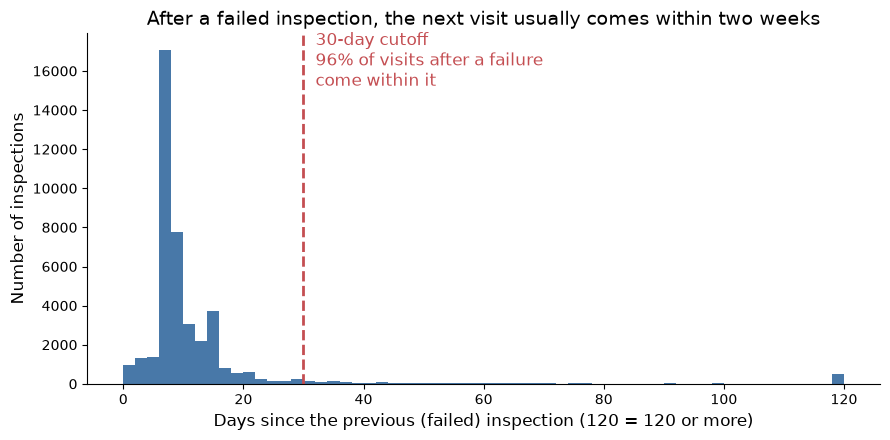

median gap after a failure: 8 days
re-inspections dropped (2016 onward): 40,360 of 98,924 inspections


In [7]:
after_fail = in_period.loc[in_period["last_fail"] == 1, "days_since_last"]
share_within = (after_fail <= F.REINSPECTION_DAYS).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(after_fail.clip(upper=120), bins=range(0, 122, 2), color="#4878a8")
ax.axvline(F.REINSPECTION_DAYS, color="#c44e52", linestyle="--", linewidth=2)
ax.text(F.REINSPECTION_DAYS + 2, ax.get_ylim()[1] * 0.85,
        f"{F.REINSPECTION_DAYS}-day cutoff\n{share_within:.0%} of visits after a failure\ncome within it",
        color="#c44e52", fontsize=12)
ax.set_title("After a failed inspection, the next visit usually comes within two weeks", fontsize=14)
ax.set_xlabel("Days since the previous (failed) inspection (120 = 120 or more)", fontsize=12)
ax.set_ylabel("Number of inspections", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../results/figures/reinspection_gap.png", dpi=150)
plt.show()

print(f"median gap after a failure: {after_fail.median():.0f} days")
print(f"re-inspections dropped (2016 onward): {int(in_period['is_reinspection'].sum()):,} of {len(in_period):,} inspections")

## 5. Privacy checks

The repo is public, so no owner names may be saved. The pull never requested them.
Inspectors sometimes write a person's name, an email or a phone number in the comments, and `clean()` masks those with `[NAME]`, `[EMAIL]` and `[PHONE]`.

The scan below counts loose patterns before and after masking. The name patterns are structural (a role word or a certificate followed by two capitalized words), so they also count ordinary phrases such as "Contact Health Department".

In [8]:
assert not F.OWNER_COLUMNS & set(raw.columns), "owner columns in the raw snapshot"
assert not F.OWNER_COLUMNS & set(table.columns), "owner columns in the model table"
assert not F.OWNER_COLUMNS & set(full.columns), "owner columns in the full inspection table"

scans = {
    "Mr./Mrs./Ms. + capitalized word": re.compile(r"\b(?:Mr|Mrs|Ms)\.?\s+[A-Z][a-z]{2,}"),
    "email-like (@ next to a letter)": re.compile(r"[A-Za-z]@[A-Za-z]|[A-Za-z]+\.[A-Za-z]+\s*@"),
    "phone-like (3-3-4 digits)": re.compile(r"\b\d{3}\D{0,3}\d{3}\D{0,3}\d{4}\b"),
    "role word + two capitalized words": re.compile(
        r"(?i:\b(?:pic|owner|manager|chef|gm|supervisor|person in charge|spoke with|met with)\b)[\s:,\-(]*[A-Z][a-z]+\s+[A-Z][a-z]+"),
    "certificate ... two capitalized words": re.compile(
        r"(?i:servsafe|certificat\w*|cfpm)[^.|]{0,40}?(?i:\b(?:for|to|of|by|name)\b)\s*[:\-]?\s*[A-Z][a-z]+\s+[A-Z][a-z]+"),
}
before = pd.Series(raw["comments"].dropna().unique())
after = pd.Series(full["comments"].unique())
print(f"{'pattern':40s} {'raw comments':>13s} {'after masking':>14s}")
for name, rx in scans.items():
    print(f"{name:40s} {int(before.str.contains(rx).sum()):13,d} {int(after.str.contains(rx).sum()):14,d}")
print("\ncomments carrying a mask:",
      {tag: int(after.str.contains(tag, regex=False).sum()) for tag in ["[NAME]", "[EMAIL]", "[PHONE]"]})

pattern                                   raw comments  after masking


Mr./Mrs./Ms. + capitalized word                      6              0


email-like (@ next to a letter)                    981             10


phone-like (3-3-4 digits)                          126              4


role word + two capitalized words                  164             61


certificate ... two capitalized words               79             72

comments carrying a mask: {'[NAME]': 1143, '[EMAIL]': 1254, '[PHONE]': 147}


What remains after masking is mostly not personal: kitchen shorthand with an `@` sign ("sink@rear prep area"), a regulation number ("105 CMR 590.000/1999"), and phrases such as "Contact Health Department" or "Certificate for Food Safety".

The masking is best effort. A regex cannot recognize every name, and an independent review with a separate name list still found a handful of name-like strings among 324,000 distinct comments. For that reason the comment text stays in `data/`, which is git-ignored and must never be published. The only comment text in the repo is the three short snippets in `results/text_examples.md`, which were read by hand.

## 6. Split and leakage checks

The split is fixed by calendar year: train 2016 to 2022, validation 2023, test 2024 onward.

The table below shows the size and fail rate of every split, test years included, as the project brief asks. These are label summaries only. No model has seen the test years, and no modeling decision uses these numbers.

In [9]:
print(table.groupby("split").agg(rows=("label_fail", "size"), fail_rate=("label_fail", "mean"),
                                 first_day=("date", "min"), last_day=("date", "max")).loc[["train", "val", "test"]].to_string())

# Every date must sit inside its split.
assert table.loc[table["split"] == "train", "year"].between(2016, 2022).all()
assert (table.loc[table["split"] == "val", "year"] == 2023).all()
assert (table.loc[table["split"] == "test", "year"] >= 2024).all()
assert set(table["split"]) == {"train", "val", "test"}

        rows  fail_rate  first_day   last_day
split                                        
train  35872   0.599521 2016-01-02 2022-12-30
val     5521   0.557689 2023-01-03 2023-12-29
test   17171   0.590006 2024-01-02 2026-11-10


In [10]:
# 1. For 3 random restaurants: prior_n is the row position, last_fail is the previous label,
#    prior_comments is the previous inspection's comments.
# 2. For 300 random restaurants: every history column equals a by-hand recomputation.
F.check_no_leakage(full, n_restaurants=3, seed=SEED)

  license 397043: 17 inspections, history features only use earlier rows  OK
  license 78169: 20 inspections, history features only use earlier rows  OK
  license 19339: 54 inspections, history features only use earlier rows  OK


  cross-check: 13 history columns match a by-hand recomputation for 300 restaurants (5,783 inspections)  OK


## 7. Save

In [11]:
from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)                 # data/ is git-ignored, so a fresh clone lacks it
full.to_parquet("../data/processed/inspections_full.parquet", index=False)   # full sequence, used for the priority list
table.to_parquet("../data/processed/model_table.parquet", index=False)
print("saved model table:", table.shape)
print(table[["inspection_id", "date", "label_fail", "prior_n", "prior_fail_rate", "last_routine_fail",
             "days_since_last", "neighborhood", "split"]].head().to_string())

saved model table: (58564, 36)
     inspection_id       date  label_fail  prior_n  prior_fail_rate  last_routine_fail  days_since_last neighborhood  split
0  112361_20161004 2016-10-04           0        2         0.000000                0.0            446.0      Allston  train
1  112361_20180927 2018-09-27           1        3         0.000000                0.0            723.0      Allston  train
2  112361_20191024 2019-10-24           0        5         0.200000                1.0            385.0      Allston  train
3  112361_20201104 2020-11-04           0        6         0.166667                0.0            377.0      Allston  train
4  112361_20210930 2021-09-30           1        7         0.142857                0.0            330.0      Allston  train
